# Hold Detector Round B

Round B starts from Round A's best weights and fine-tunes on our dataset from our local climbing gyms.

## Cell 1: Setup

Our chosen settings:
- `STAGE2_VERSION`: the stage 2 Roboflow version
- `ROUND_A`: round A's weights
- `BATCH = 3` and `IMGSZ = 1280`, the same as round A, so the comparison is fair (we use batch 3 since batch 4 ran out of mem on L4 GPU)

In [ ]:
!pip install -q roboflow ultralytics
import os, glob, shutil, json, yaml
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from google.colab import drive, userdata

drive.mount('/content/drive')
BASE = '/content/drive/MyDrive/ECS-174-Project'
RESULTS_DIR = f'{BASE}/detector'
META_CSV = f'{BASE}/metadata.csv'
WORKSPACE = 'bouldering-hold-labeling'
STAGE1_PROJECT, STAGE1_VERSION = 'bouldering-holds-stage-1', 3
STAGE2_PROJECT, STAGE2_VERSION = 'bouldering-holds-stage-2', 7
BATCH, IMGSZ = 3, 1280
RUN_NAME = 'roundB_1280'

ROUND_A = f'{RESULTS_DIR}/roundA_best.pt'
if not os.path.exists(ROUND_A):
    shutil.copy(f'{RESULTS_DIR}/roundA_1280/weights/best.pt', ROUND_A)
    print('Made protected copy of round A weights')
print('Round A weights:', ROUND_A)

Mounted at /content/drive
Made protected copy of round A weights
Round A weights: /content/drive/MyDrive/ECS-174-Project/detector/roundA_best.pt
GPU: NVIDIA L4


## Cell 2: Download the datasets

Downloads the gym dataset and round A's public dataset

In [ ]:
from roboflow import Roboflow
rf = Roboflow(api_key=userdata.get('ROBOFLOW_API_KEY'))
gym = rf.workspace(WORKSPACE).project(STAGE2_PROJECT).version(STAGE2_VERSION).download('yolov8')
public = rf.workspace(WORKSPACE).project(STAGE1_PROJECT).version(STAGE1_VERSION).download('yolov8')

def fix_yaml(location):
    path = os.path.join(location, 'data.yaml')
    data = yaml.safe_load(open(path))
    data.update({'path': location, 'train': 'train/images', 'val': 'valid/images', 'test': 'test/images'})
    yaml.safe_dump(data, open(path, 'w'))
    return path, data['names']

GYM_YAML, GYM_NAMES = fix_yaml(gym.location)
PUBLIC_YAML, PUBLIC_NAMES = fix_yaml(public.location)
print('Gym classes:', GYM_NAMES)
print('Public classes:', PUBLIC_NAMES)

loading Roboflow workspace...
loading Roboflow project...
Exporting format yolov8 in progress : 95.0%
Version export complete for yolov8 format



Extracting Dataset Version Zip to bouldering-holds-stage-2-7 in yolov8:: 100%|██████████| 195/195 [00:00<00:00, 1420.17it/s]


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to bouldering-holds-stage-1-3 in yolov8:: 100%|██████████| 1932/1932 [00:00<00:00, 2179.55it/s]


Gym classes: ['black-hold', 'blue-hold', 'down', 'green-hold', 'orange-hold', 'pink-hold', 'purple-hold', 'red-hold', 'teal-hold', 'volume', 'yellow-hold']
Public classes: ['Hold', 'Volume']


In [ ]:
# Cell 2b: rebuild the gym dataset's YOLO labels from the COCO export since the auto labels don't convert properly
!pip install -q pycocotools
import cv2, json, types
from collections import Counter, defaultdict
from pycocotools import mask as mask_utils

coco_ds = rf.workspace(WORKSPACE).project(STAGE2_PROJECT).version(STAGE2_VERSION).download(
    'coco-segmentation', location='/content/gym-coco', overwrite=True)
OUT = '/content/gym-yolo-from-coco'
shutil.rmtree(OUT, ignore_errors=True)
name_to_idx = {n: i for i, n in enumerate(GYM_NAMES)}          # same class order as the YOLOv8 export

def seg_to_mask(seg):
    '''COCO RLE mask (compressed string or uncompressed counts list) -> binary image.'''
    h, w = seg['size']
    rle = dict(seg)
    if isinstance(rle['counts'], list):                          # uncompressed RLE
        rle = mask_utils.frPyObjects(rle, h, w)
    elif isinstance(rle['counts'], str):                         # compressed RLE as text
        rle['counts'] = rle['counts'].encode('ascii')
    return np.ascontiguousarray(mask_utils.decode(rle), dtype=np.uint8)

def outlines(seg):
    '''Polygon labels as they are; RLE masks traced into outlines.'''
    if isinstance(seg, dict):
        cs, _ = cv2.findContours(seg_to_mask(seg), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        return [c.reshape(-1, 2).astype(np.float32) for c in cs if len(c) >= 3]
    return [np.array(p, np.float32).reshape(-1, 2) for p in seg if len(p) >= 6]

stats = Counter()
for split in ['train', 'valid', 'test']:
    coco_file = f'{coco_ds.location}/{split}/_annotations.coco.json'
    if not os.path.exists(coco_file):
        continue
    coco = json.load(open(coco_file))
    cats = {c['id']: c['name'] for c in coco['categories']}
    anns = defaultdict(list)
    for a in coco['annotations']:
        anns[a['image_id']].append(a)
    os.makedirs(f'{OUT}/{split}/images', exist_ok=True)
    os.makedirs(f'{OUT}/{split}/labels', exist_ok=True)
    for im in coco['images']:
        shutil.copy(f"{coco_ds.location}/{split}/{im['file_name']}", f"{OUT}/{split}/images/{im['file_name']}")
        W, H = im['width'], im['height']
        lines = []
        for a in anns[im['id']]:
            name = cats[a['category_id']]
            if name not in name_to_idx:
                stats['skipped (class not in the YOLO export)'] += 1
                continue
            parts = outlines(a['segmentation'])
            if not parts:
                stats['skipped (empty outline)'] += 1
                continue
            p = max(parts, key=cv2.contourArea)                       # YOLO takes one outline per object
            stats['objects with several parts (largest kept)'] += len(parts) > 1
            q = cv2.approxPolyDP(p.reshape(-1, 1, 2), 1.0, True).reshape(-1, 2)
            p = q if len(q) >= 3 else p
            stats['from RLE mask' if isinstance(a['segmentation'], dict) else 'from polygon'] += 1
            xy = np.clip(p / [W, H], 0, 1)
            lines.append(f'{name_to_idx[name]} ' + ' '.join(f'{v:.6f}' for v in xy.ravel()))
        stem = os.path.splitext(im['file_name'])[0]
        with open(f'{OUT}/{split}/labels/{stem}.txt', 'w') as f:
            f.write('\n'.join(lines) + ('\n' if lines else ''))

GYM_YAML = f'{OUT}/data.yaml'
yaml.safe_dump({'path': OUT, 'train': 'train/images', 'val': 'valid/images', 'test': 'test/images',
                'nc': len(GYM_NAMES), 'names': GYM_NAMES}, open(GYM_YAML, 'w'))
gym = types.SimpleNamespace(location=OUT)
print(dict(stats))
print({s: len(os.listdir(f'{OUT}/{s}/images')) for s in ['train', 'valid', 'test'] if os.path.isdir(f'{OUT}/{s}/images')}, 'images')

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/gym-coco in coco-segmentation:: 100%|██████████| 100/100 [00:00<00:00, 796.22it/s]


{'objects with several parts (largest kept)': 104, 'from RLE mask': 9571, 'from polygon': 970}
{'train': 66, 'valid': 15, 'test': 14} images


## Cell 3: Train round B

Starts from round A's weights.

Settings:
- `hsv_h=0.0`: no hue changes during augmentation, because the classes are colors.
- `hsv_s=0.3`: smaller saturation changes to not mess up colors.
- `hsv_v=0.4`: brightness changes stay since lighting changes between walls.
- `fliplr=0.5`: left-right flips are fine.
- `imgsz=1280`, `batch=3`, `seed=0`, `patience=20`, `cache='disk'`: same as round A

In [ ]:
from ultralytics import YOLO

def train_round_b(epochs=100, patience=20):
    last = Path(RESULTS_DIR) / RUN_NAME / 'weights' / 'last.pt'
    if last.exists():
        print(f'Resuming {RUN_NAME} from {last}')
        try:
            YOLO(str(last)).train(resume=True)
        except AssertionError as e:
            print(f'{RUN_NAME} already finished: {e}')
    else:
        YOLO(ROUND_A).train(
            data=GYM_YAML, imgsz=IMGSZ, epochs=epochs, patience=patience, batch=BATCH,
            hsv_h=0.0, hsv_s=0.3, hsv_v=0.4, fliplr=0.5,
            cache='disk', seed=0, project=RESULTS_DIR, name=RUN_NAME, exist_ok=True,
        )
    return Path(RESULTS_DIR) / RUN_NAME

run_b = train_round_b()
ROUND_B = str(run_b / 'weights' / 'best.pt')
print('Round B best weights:', ROUND_B)

Ultralytics 8.4.198 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=3, bgr=0.0, box=7.5, cache=disk, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/gym-yolo-from-coco/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.3, hsv_v=0.4, imgsz=1280, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/drive/MyDrive/ECS-174-Project/detector/roundA_best.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=ro

In [ ]:
r = pd.read_csv(f'{RESULTS_DIR}/{RUN_NAME}/results.csv')
r.columns = r.columns.str.strip()
print('best epoch:', int(r.loc[r['metrics/mAP50-95(M)'].idxmax(), 'epoch']))
print(r[['epoch', 'metrics/mAP50(M)', 'metrics/mAP50-95(M)']].tail(12).round(3).to_string(index=False))

best epoch: 87
 epoch  metrics/mAP50(M)  metrics/mAP50-95(M)
    89             0.917                0.658
    90             0.916                0.653
    91             0.915                0.649
    92             0.914                0.645
    93             0.912                0.642
    94             0.913                0.647
    95             0.911                0.649
    96             0.912                0.652
    97             0.913                0.651
    98             0.913                0.651
    99             0.911                0.649
   100             0.912                0.649


## Cell 5: Round B per-class scores (validation and test)

Mask mAP50 and mask mAP50-95 per class. `max_det=500` because walls hold up to about 400 holds.

In [ ]:
def seg_metrics(weights, data_yaml, split, single_cls=False, label=''):
    model = YOLO(weights)
    m = model.val(data=data_yaml, imgsz=IMGSZ, split=split, max_det=500, batch=BATCH * 2,
                  single_cls=single_cls, verbose=False, plots=True)
    rows = [{'class': 'all', 'mask_mAP50': m.seg.map50, 'mask_mAP50_95': m.seg.map}]
    if not single_cls:
        for i, c in enumerate(m.ap_class_index):
            _, _, ap50, ap = m.seg.class_result(i)
            rows.append({'class': model.names[int(c)], 'mask_mAP50': ap50, 'mask_mAP50_95': ap})
    df = pd.DataFrame(rows).round(3)
    df.insert(0, 'split', split)
    df.insert(0, 'eval', label)
    return df, m

val_b, _ = seg_metrics(ROUND_B, GYM_YAML, 'val', label='roundB gym')
test_b, m_test_b = seg_metrics(ROUND_B, GYM_YAML, 'test', label='roundB gym')
test_b['test_objects'] = test_b['class'].map(lambda c: counts['test'].get(c, sum(counts['test'].values())))
print('Validation:\n', val_b.to_string(index=False))
print('\nTest:\n', test_b.to_string(index=False))

Ultralytics 8.4.198 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
YOLOv8m-seg summary (fused): 105 layers, 27,228,753 parameters, 0 gradients, 104.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3346.9±825.5 MB/s, size: 1128.1 KB)
val: Scanning /content/gym-yolo-from-coco/valid/labels.cache... 15 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 15/15 5.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 1.0s/it 3.0s
                   all         15       1437       0.89        0.9       0.93      0.824      0.881       0.89       0.92      0.639
Speed: 12.0ms preprocess, 64.5ms inference, 0.1ms loss, 8.9ms postprocess per image
Results saved to /content/runs/segment/val
Ultralytics 8.4.198 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
YOLOv8m-seg summary (fused): 105 layers, 27,228,753 parameters, 0 gradients, 104.3 GFL

## Cell 5: Round A vs Round B

With `single_cls=True`, Ultralytics treats every label and every prediction as one class so both models are scored only on finding holds.

In [ ]:
results = []
for label, w in [('roundA', ROUND_A), ('roundB', ROUND_B)]:
    for data_label, data_yaml in [('gym test', GYM_YAML), ('public test', PUBLIC_YAML)]:
        df, _ = seg_metrics(w, data_yaml, 'test', single_cls=True, label=label)
        results.append({'model': label, 'test set': data_label,
                        'mask_mAP50': df.mask_mAP50.iloc[0], 'mask_mAP50_95': df.mask_mAP50_95.iloc[0]})
compare = pd.DataFrame(results).pivot(index='model', columns='test set', values=['mask_mAP50', 'mask_mAP50_95'])
print(compare.round(3).to_string())

Ultralytics 8.4.198 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
YOLOv8m-seg summary (fused): 105 layers, 27,223,542 parameters, 0 gradients, 104.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3006.0±912.1 MB/s, size: 806.9 KB)
val: Scanning /content/gym-yolo-from-coco/test/labels... 14 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 14/14 403.0it/s 0.0s
val: New cache created: /content/gym-yolo-from-coco/test/labels.cache
WARNING ⚠️ Skipping labels of classes the model (nc=2) cannot predict.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 1.1it/s 2.7s
                   all         14       1333      0.973      0.941      0.981      0.854      0.952      0.917      0.957       0.62
Speed: 8.6ms preprocess, 45.6ms inference, 0.0ms loss, 6.9ms postprocess per image
Results saved to /content/runs/segment/val-3
Ultralytics 8.4.198 🚀 Python-3.13.16

## Cell 7: Color Confusion Matrix

% of each true class (rows) predicted as each class (columns):
             black-hold  blue-hold  down  green-hold  orange-hold  pink-hold  purple-hold  red-hold  teal-hold  volume  yellow-hold  background
black-hold           84          4     2           1            0          0            6         0          2       0            0           0
blue-hold             1         96     0           0            0          0            1         0          2       0            0           0
down                  4          0    89           0            0          0            4         0          0       0            4           0
green-hold            1          0     0          96            0          0            0         0          3       0            0           0
orange-hold           0          0     0           0           70          2            1        27          0       0            0           0
pink-hold             0          0     0           0            1        

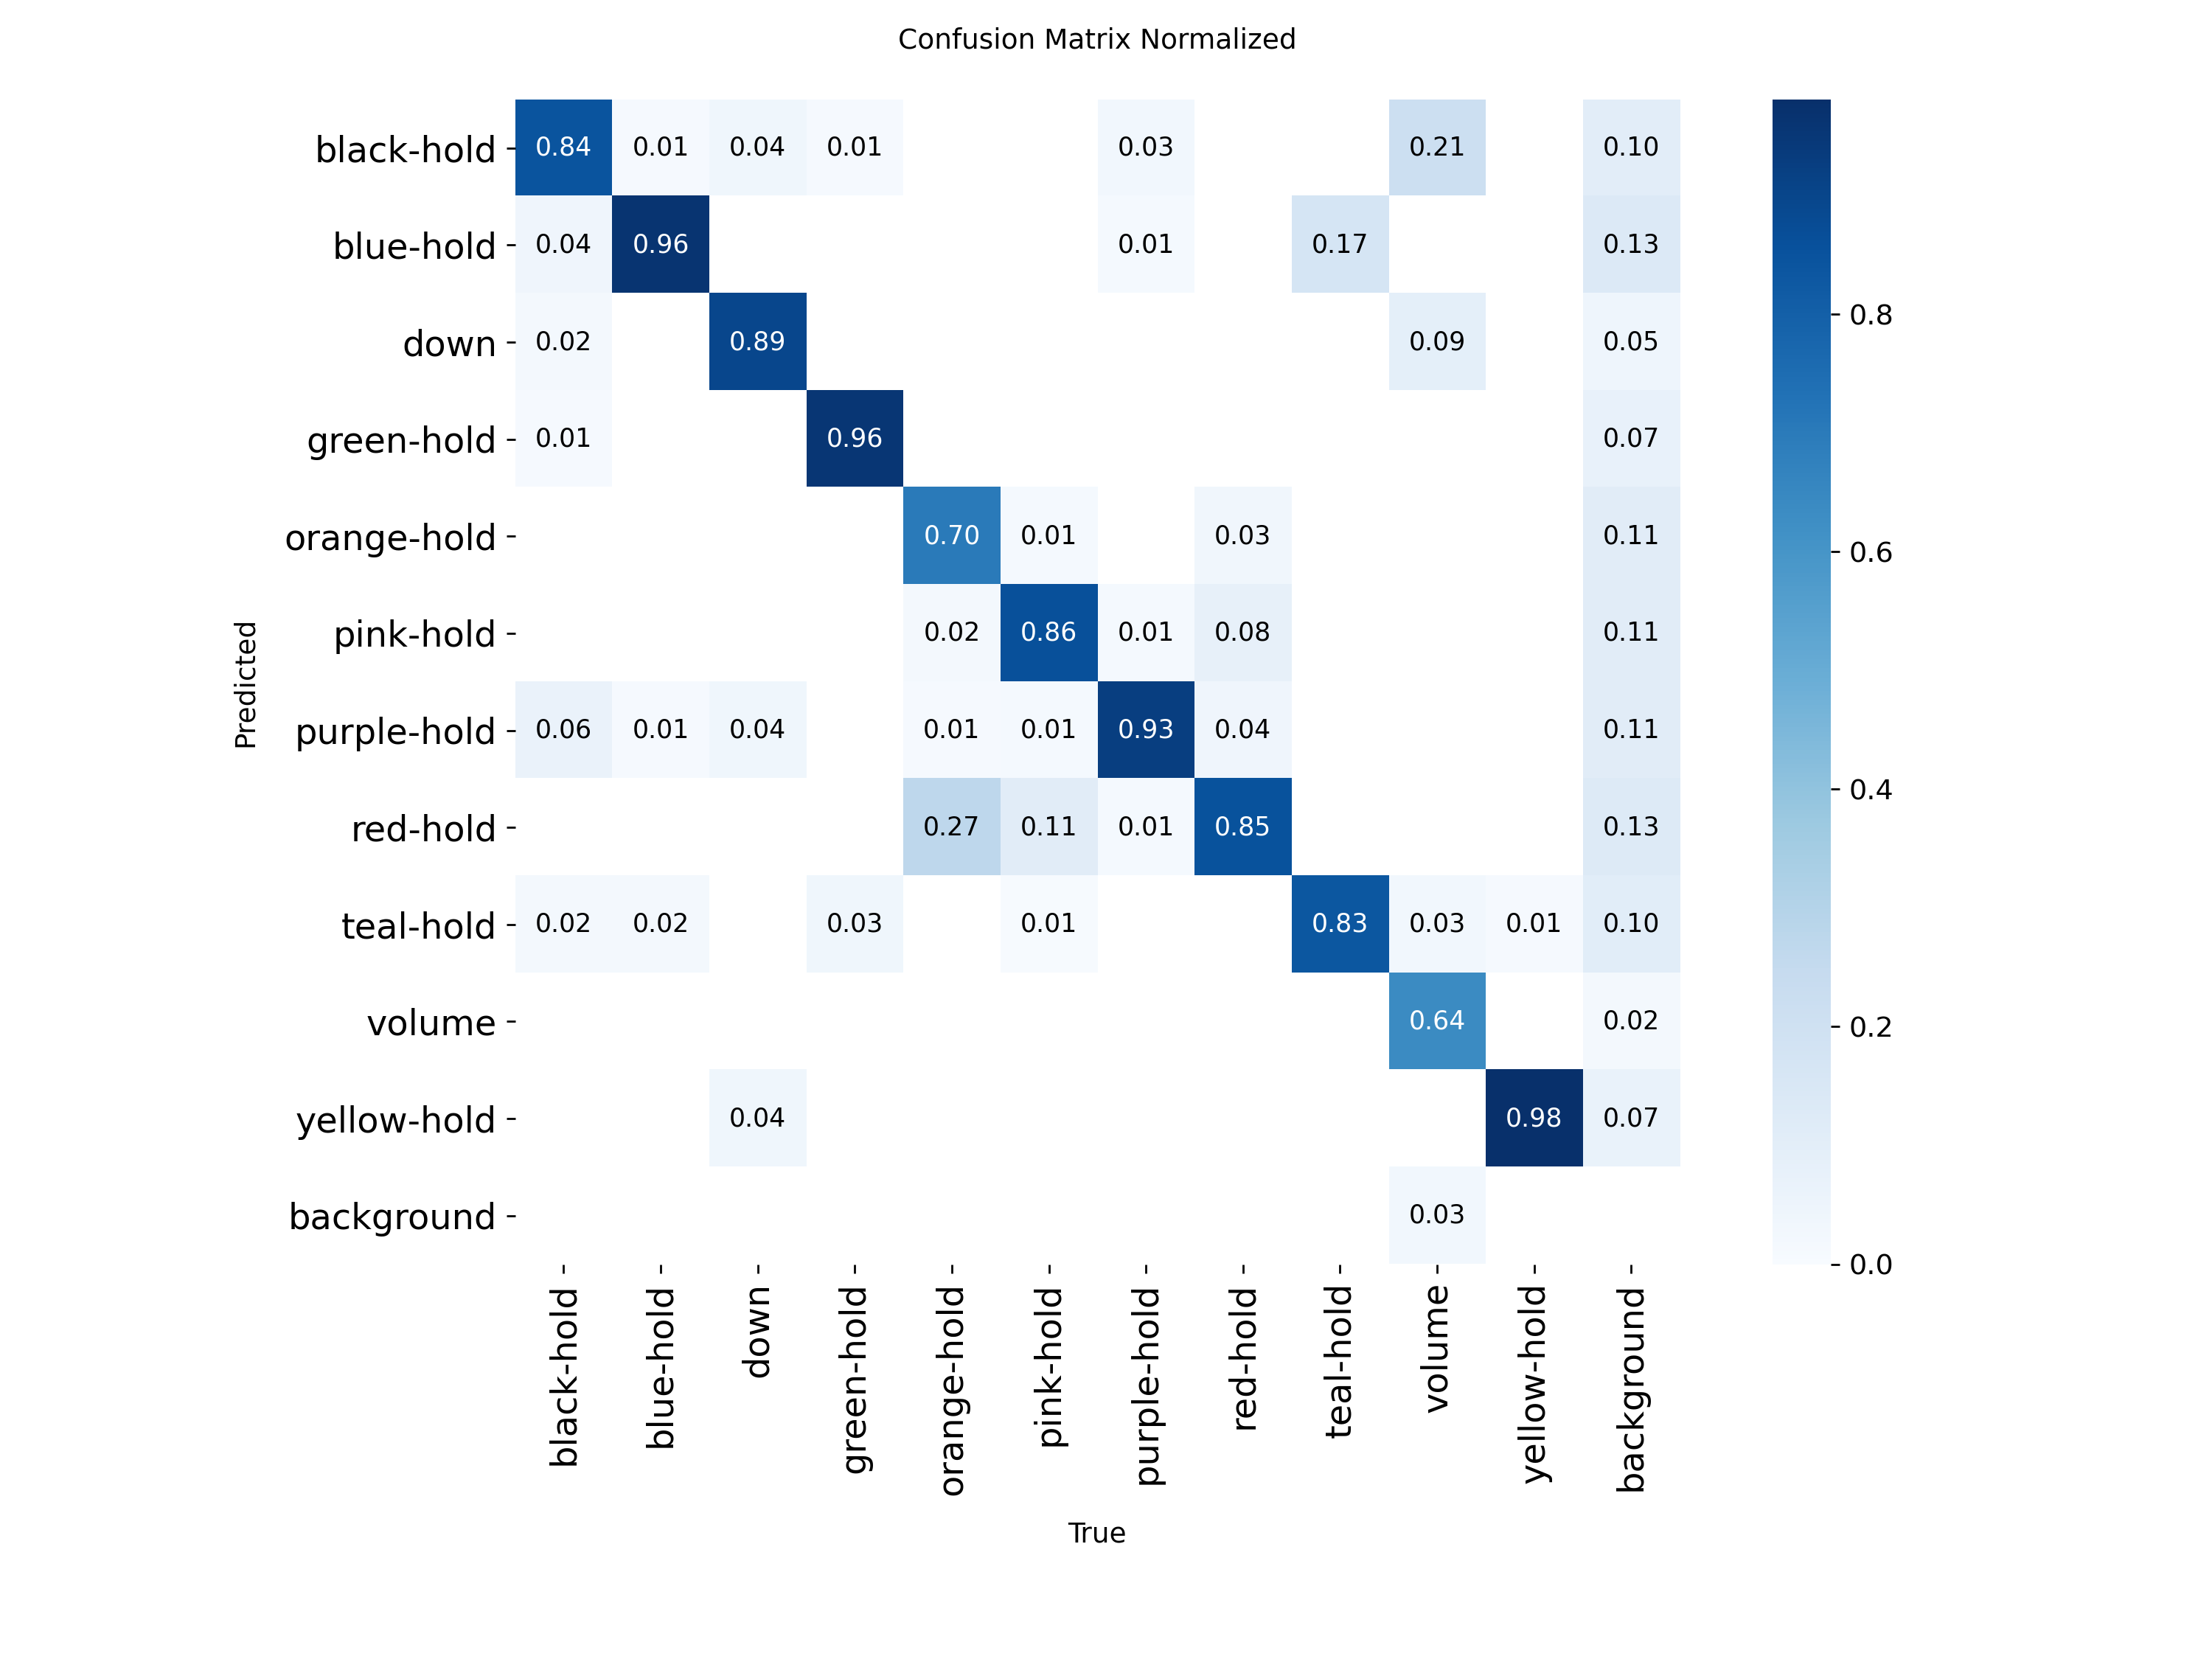

In [ ]:
from IPython.display import Image, display
cm = m_test_b.confusion_matrix.matrix
names = [m_test_b.names[i] for i in range(len(m_test_b.names))] + ['background']
conf = pd.DataFrame(cm.T, index=names, columns=names)        # rows = true, cols = predicted
conf = conf.loc[conf.sum(axis=1) > 0, conf.sum(axis=0) > 0]
conf_pct = (conf.div(conf.sum(axis=1), axis=0) * 100).round(0).astype(int)
conf_pct.to_csv(f'{RESULTS_DIR}/{RUN_NAME}/confusion_test.csv')
print('% of each true class (rows) predicted as each class (columns):')
print(conf_pct.to_string())
png = sorted(glob.glob(f'{m_test_b.save_dir}/confusion_matrix_normalized.png'))
if png:
    display(Image(filename=png[0], width=700))

## Cell 8: Log the results

Appends round B's validation and test scores and the round A vs B comparison to `detector/results_log.csv`

In [ ]:
LOG = f'{RESULTS_DIR}/results_log.csv'
rows = []
for df in (val_b, test_b):
    for r in df.to_dict('records'):
        rows.append({'run': RUN_NAME, 'model': 'roundA_best.pt -> gym', 'imgsz': IMGSZ, 'split': r['split'],
                     'class': r['class'], 'mask_mAP50': r['mask_mAP50'], 'mask_mAP50_95': r['mask_mAP50_95']})
for r in results:
    rows.append({'run': r['model'], 'model': 'single_cls', 'imgsz': IMGSZ, 'split': r['test set'],
                 'class': 'any hold', 'mask_mAP50': r['mask_mAP50'], 'mask_mAP50_95': r['mask_mAP50_95']})
log = pd.DataFrame(rows)
log.to_csv(LOG, mode='a', header=not os.path.exists(LOG), index=False)
print(log.to_string(index=False))

        run                 model  imgsz       split       class  mask_mAP50  mask_mAP50_95
roundB_1280 roundA_best.pt -> gym   1280         val         all       0.920          0.639
roundB_1280 roundA_best.pt -> gym   1280         val  black-hold       0.898          0.612
roundB_1280 roundA_best.pt -> gym   1280         val   blue-hold       0.976          0.634
roundB_1280 roundA_best.pt -> gym   1280         val        down       0.932          0.646
roundB_1280 roundA_best.pt -> gym   1280         val  green-hold       0.991          0.629
roundB_1280 roundA_best.pt -> gym   1280         val orange-hold       0.906          0.659
roundB_1280 roundA_best.pt -> gym   1280         val   pink-hold       0.936          0.608
roundB_1280 roundA_best.pt -> gym   1280         val purple-hold       0.939          0.719
roundB_1280 roundA_best.pt -> gym   1280         val    red-hold       0.889          0.611
roundB_1280 roundA_best.pt -> gym   1280         val   teal-hold       0.813    